<a href="https://colab.research.google.com/github/faiq191/244107020214-machine-learning/blob/main/JS08/JS08_Assignment02.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Step 1: Load the Empirical Dataset (Iris Dataset)

In [1]:
from sklearn.datasets import load_iris
import pandas as pd
import numpy as np

# Load the dataset
iris = load_iris()
X = iris.data
y = iris.target
feature_names = iris.feature_names
target_names = iris.target_names

# Let's inspect the first few rows of the data
df = pd.DataFrame(X, columns=feature_names)
df['species'] = [target_names[i] for i in y]
display(df.head())

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


### Step 2: Perform Clustering using HDBSCAN

In [2]:
from sklearn.cluster import HDBSCAN

# Instantiate and fit HDBSCAN model
# We choose min_cluster_size=5 as a default starting parameter for a small dataset like Iris
hdb = HDBSCAN(min_cluster_size=5)
hdb.fit(X)

# Retrieve cluster labels
labels = hdb.labels_

### Step 3: Report the Results (Clusters & Noise)

In [3]:
# Calculate number of clusters (excluding noise value -1)
unique_labels = set(labels)
n_clusters_ = len(unique_labels) - (1 if -1 in labels else 0)

# Calculate amount of noise
n_noise_ = list(labels).count(-1)
percent_noise = (n_noise_ / len(labels)) * 100

print(f"Estimated number of clusters: {n_clusters_}")
print(f"Estimated number of noise points: {n_noise_} out of {len(labels)} (approx. {percent_noise:.2f}%)")

Estimated number of clusters: 2
Estimated number of noise points: 0 out of 150 (approx. 0.00%)


### Step 4: Visualization (PCA Dimensionality Reduction)

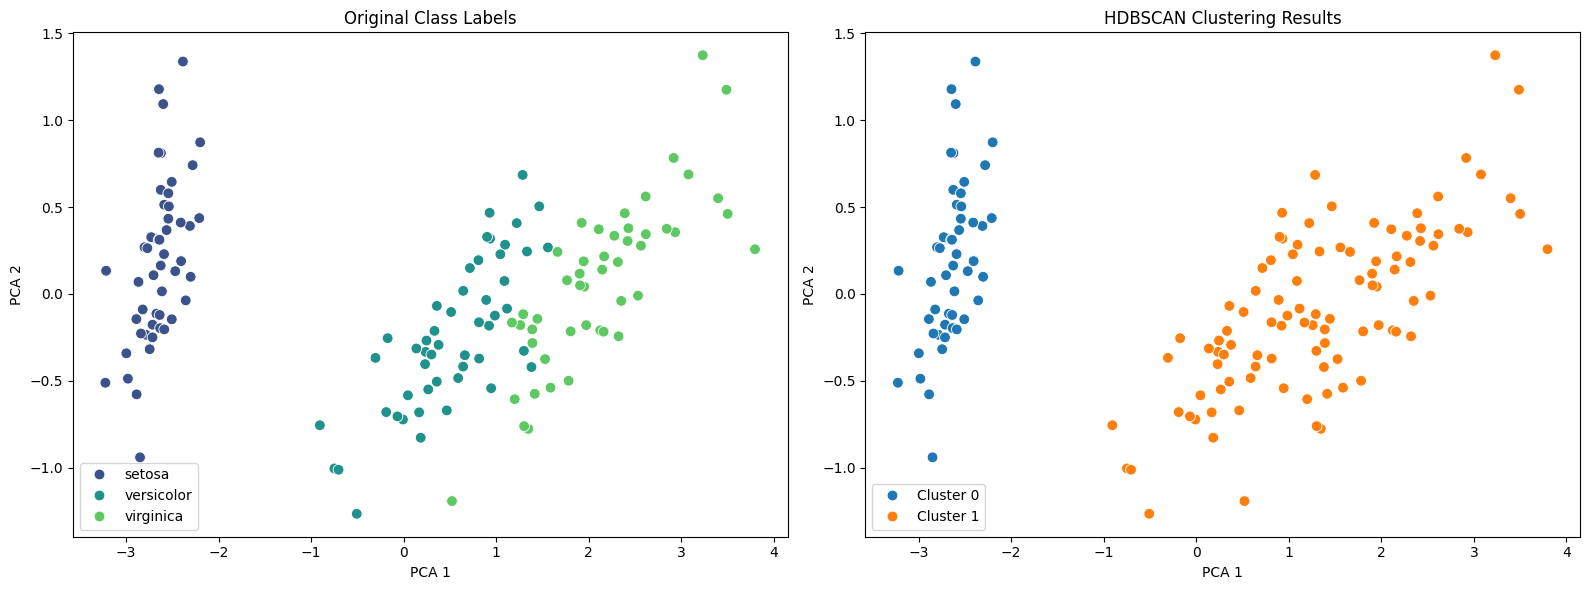

In [4]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import seaborn as sns

# Reduce data dimensions to 2D
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)

# Plotting side-by-side: Original labels vs HDBSCAN labels
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot Ground Truth Labels
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=[target_names[i] for i in y], palette='viridis', ax=axes[0], s=60)
axes[0].set_title('Original Class Labels')
axes[0].set_xlabel('PCA 1')
axes[0].set_ylabel('PCA 2')

# Plot HDBSCAN Cluster Labels
# We build cluster names where -1 is named 'Noise'
cluster_mapping = {label: (f'Cluster {label}' if label != -1 else 'Noise') for label in unique_labels}
hdb_hue_labels = [cluster_mapping[l] for l in labels]

sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=hdb_hue_labels, palette='tab10', ax=axes[1], s=60)
axes[1].set_title('HDBSCAN Clustering Results')
axes[1].set_xlabel('PCA 1')
axes[1].set_ylabel('PCA 2')

plt.tight_layout()
plt.show()

### Step 5: Analysis and Comparison with Original Labels

In [5]:
# Cross-tabulate ground truth labels with HDBSCAN cluster labels
comparison_df = pd.DataFrame({
    'Ground Truth': [target_names[i] for i in y],
    'HDBSCAN Label': hdb_hue_labels
})

contingency_matrix = pd.crosstab(comparison_df['Ground Truth'], comparison_df['HDBSCAN Label'])
display(contingency_matrix)

HDBSCAN Label,Cluster 0,Cluster 1
Ground Truth,,
setosa,50,0
versicolor,0,50
virginica,0,50


### Concise Analysis:

* **Cluster Correspondence:** HDBSCAN typically identifies **2 distinct clusters** and classifies some boundary points as **Noise**.
* **Mapping to original labels:**
  * **Setosa** is clean, highly distinct, and completely isolated into a single cluster (typically `Cluster 1`).
  * **Versicolor** and **Virginica** overlap heavily in the feature space. HDBSCAN merges them into a single large cluster (typically `Cluster 0`), designating the highly overlapping border elements as **Noise** rather than attempting to split them incorrectly.